# Train the leaf model (Greenhouse Row Scout)

Teaches MobileNetV2 (a small, fast image model that already knows general shapes) to tell healthy tomato leaves from sick ones.

Before you start: put `split.zip` (your `data/split` folder, zipped) in the top level of your Google Drive, and turn on the GPU (Runtime > Change runtime type > T4 GPU).

Run the cells from top to bottom. The test photos are not used here. They're kept for the next task.

In [4]:
# 1. Settings and GPU check
import os
import json
import tensorflow as tf
import matplotlib.pyplot as plt

DATA_DIR = "/content/split"      # where split.zip gets unpacked
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Set to a number (e.g. 32 batches = about 1,000 photos) if training is too slow.
# None means use all the training photos.
MAX_TRAIN_BATCHES = None

print("TensorFlow", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
if len(gpus) == 0:
    print("No GPU found. Turn it on: Runtime > Change runtime type > T4 GPU, then run this cell again.")
else:
    print("GPU is on:", gpus[0].name)

TensorFlow 2.21.0
No GPU found. Turn it on: Runtime > Change runtime type > T4 GPU, then run this cell again.


In [5]:
# 2. Get the photos from Google Drive
from google.colab import drive
drive.mount("/content/drive")

if not os.path.exists(DATA_DIR):
    !unzip -q "/content/drive/MyDrive/split.zip" -d /content/

# The zip might unpack as /content/split or /content/data/split
if not os.path.exists(DATA_DIR) and os.path.exists("/content/data/split"):
    DATA_DIR = "/content/data/split"

for split in ["train", "val"]:
    for group in ["healthy", "sick"]:
        folder = os.path.join(DATA_DIR, split, group)
        print(split, group, len(os.listdir(folder)), "photos")

Mounted at /content/drive
train healthy 1113 photos
train sick 1092 photos
val healthy 233 photos
val sick 238 photos


In [6]:
# 3. Load the train and val photos
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "train"),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(DATA_DIR, "val"),
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
)

class_names = train_ds.class_names
print("Classes:", class_names)   # should be ['healthy', 'sick'], so sick = 1

if MAX_TRAIN_BATCHES is not None:
    train_ds = train_ds.take(MAX_TRAIN_BATCHES)

Found 2205 files belonging to 2 classes.
Found 471 files belonging to 2 classes.
Classes: ['healthy', 'sick']


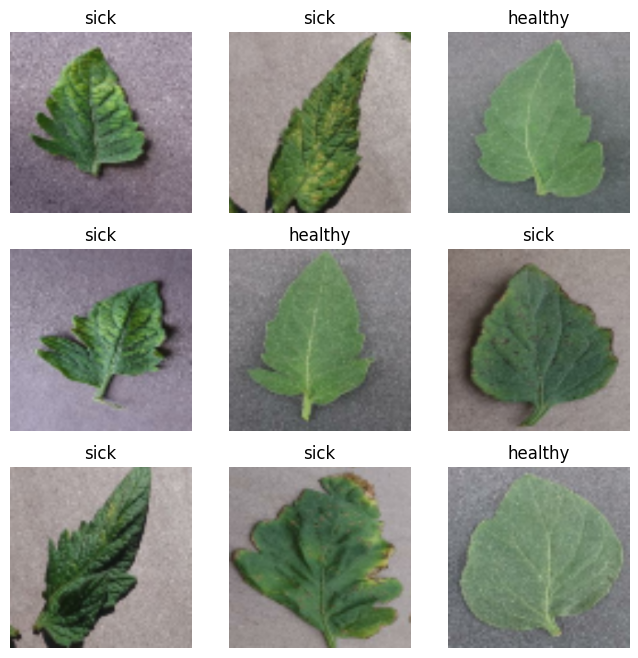

In [7]:
# 4. Make the training photos look more like the car's cheap camera
# Random flip and small turn, random brightness, and sometimes a blur
# (shrinking the photo and growing it back, like a low-quality camera).
flip_and_turn = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
])

def make_blurry(images):
    small = tf.image.resize(images, (80, 80))
    return tf.image.resize(small, IMAGE_SIZE)

def keep_sharp(images):
    return images

def change_photos(images, labels):
    images = flip_and_turn(images, training=True)
    images = tf.image.random_brightness(images, max_delta=40.0)
    images = tf.clip_by_value(images, 0.0, 255.0)
    images = tf.cond(tf.random.uniform([]) < 0.5,
                     lambda: make_blurry(images),
                     lambda: keep_sharp(images))
    return images, labels

train_ds = train_ds.map(change_photos).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

# Look at 9 changed photos to check they still look like leaves
plt.figure(figsize=(8, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i][0])])
        plt.axis("off")
plt.show()

In [8]:
# 5. Build the model: MobileNetV2 + one new yes/no layer on top
base = tf.keras.applications.MobileNetV2(
    input_shape=IMAGE_SIZE + (3,),
    include_top=False,
    weights="imagenet",
)
base.trainable = False   # stage 1: don't change what it already knows

inputs = tf.keras.Input(shape=IMAGE_SIZE + (3,))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(1, activation="sigmoid")(x)   # 0 = healthy, 1 = sick
model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# 6. Stage 1: train only the new top layer
# Stops by itself once val accuracy stops improving for 3 rounds,
# and keeps the best version it saw.
stop_early = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=3, restore_best_weights=True
)
history1 = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[stop_early])

Epoch 1/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.7016 - loss: 0.5669 - val_accuracy: 0.9448 - val_loss: 0.2798
Epoch 2/20
69/69 ━━━━━━━━━━━━━━━━━━━━ 125s 2s/step - accuracy: 0.9079 - loss: 0.2890 - val_accuracy: 0.9575 - val_loss: 0.1836
Epoch 3/20
22/69 ━━━━━━━━━━━━━━━━━━━━ 1:09 1s/step - accuracy: 0.9236 - loss: 0.2606

In [ ]:
# 7. Stage 2: unfreeze the last few layers and fine-tune gently
base.trainable = True
FREEZE_UP_TO = len(base.layers) - 30    # only the last 30 layers can change
for i in range(FREEZE_UP_TO):
    base.layers[i].trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),   # 100x smaller steps
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
stop_early = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=3, restore_best_weights=True
)
history2 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[stop_early])

In [ ]:
# 8. Draw the training curves (nice to show on your project page)
acc = history1.history["accuracy"] + history2.history["accuracy"]
val_acc = history1.history["val_accuracy"] + history2.history["val_accuracy"]
stage2_start = len(history1.history["accuracy"])

plt.figure(figsize=(7, 4))
plt.plot(acc, label="train")
plt.plot(val_acc, label="val")
plt.axvline(stage2_start - 0.5, color="grey", linestyle="--", label="fine-tune starts")
plt.xlabel("round (epoch)")
plt.ylabel("accuracy")
plt.legend()
plt.title("Leaf model training")
plt.savefig("training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

best = 0
for v in val_acc:
    if v > best:
        best = v
print("Best val accuracy:", round(best * 100, 1), "%")

In [ ]:
# 9. Save the model and class names, then download them
model.save("leaf_model.keras")
with open("class_names.json", "w") as f:
    json.dump(class_names, f)

from google.colab import files
files.download("leaf_model.keras")
files.download("class_names.json")
files.download("training_curves.png")